# Faster-Whisper local ASR

In [3]:
import librosa
import numpy as np
import noisereduce as nr
import webrtcvad
import pyloudnorm as pyln
from scipy.signal import butter, lfilter
import collections
import numpy as np
import whisper
from faster_whisper import WhisperModel
import torch, torchaudio
import matplotlib.pyplot as plt
import time
import IPython.display as ipd

C:\Users\MATTIA\AppData\Roaming\Python\Python314\site-packages\webrtcvad.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Full pieline

### functions

In [4]:
def load_audio(path, target_sr=16000):
    audio, sr = librosa.load(path, sr=target_sr, mono=True)
    audio = librosa.util.normalize(audio)
    return audio, target_sr

In [5]:
def reduce_noise(audio, sr):
    reduced = nr.reduce_noise(
        y=audio,
        sr=sr,
        stationary=False,
        prop_decrease=0.8
    )
    return reduced

In [6]:
def frame_generator(audio, frame_duration_ms, sr):
    frame_length = int(sr * frame_duration_ms / 1000)
    num_frames = len(audio) // frame_length
    for i in range(num_frames):
        start = i * frame_length
        end = start + frame_length
        yield audio[start:end]

def apply_vad(audio, sr, aggressiveness=2):
    vad = webrtcvad.Vad(aggressiveness)
    frame_duration = 30  # ms
    frame_length = int(sr * frame_duration / 1000)
    frames = list(frame_generator(audio, frame_duration, sr))
    voiced_audio = []

    for frame in frames:
        if len(frame) != frame_length:
            continue  # skip incomplete frames
        pcm_frame = (frame * 32768).astype(np.int16).tobytes()
        if vad.is_speech(pcm_frame, sr):
            voiced_audio.append(frame)

    if voiced_audio:
        return np.concatenate(voiced_audio)
    else:
        return np.array([], dtype=np.float32)    

In [7]:
def apply_agc(audio, target_rms=0.1, eps=1e-6):
    rms = np.sqrt(np.mean(audio**2))
    gain = target_rms / (rms + eps)
    audio = audio * gain
    return np.clip(audio, -1.0, 1.0)
# more advanced
def loudness_normalization(audio, sr, target_lufs=-23.0):
    meter = pyln.Meter(sr)
    loudness = meter.integrated_loudness(audio)
    normalized = pyln.normalize.loudness(audio, loudness, target_lufs)
    return normalized

In [8]:
def butter_bandpass(lowcut, highcut, sr, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass_filter(audio, sr, lowcut=100.0, highcut=6000.0):
    b, a = butter_bandpass(lowcut, highcut, sr)
    filtered = lfilter(b, a, audio)
    return filtered

In [9]:
def chunk_audio(audio, sr, chunk_size=30, overlap=2):
    chunk_len = chunk_size * sr
    overlap_len = overlap * sr
    chunks = []

    start = 0
    while start < len(audio):
        end = start + chunk_len
        chunks.append(audio[start:end])
        start += chunk_len - overlap_len

    return chunks

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# whisper
model_w = whisper.load_model("tiny")
def transcribe_chunk_w(chunk, lang="en", prompt=None):
    if isinstance(chunk, np.ndarray):
        chunk = chunk.astype(np.float32)
    result = model_w.transcribe(
        chunk,
        language=lang,
        beam_size=3,
        initial_prompt=prompt if prompt else ""
    )
    return result["text"]

# faster-whisper
model_fw = WhisperModel("tiny", device=device)
def transcribe_chunk_fw(chunk, lang="en", prompt=None):
    segments, info = model_fw.transcribe(
        chunk,
        beam_size=3,
        temperature=0.0,
        initial_prompt=prompt if prompt else "",
        condition_on_previous_text=False
    )
    return " ".join([seg.text for seg in segments])

In [11]:
def asr_pipeline(audio_path, lang, prompt, faster=False):
    audio, sr = load_audio(audio_path)
    # 1. Bandpass filter
    audio = apply_bandpass_filter(audio, sr)
    # 2. Mild noise reduction
    audio = reduce_noise(audio, sr)
    # 3. Automatic gain control
    audio = apply_agc(audio)
    # 4. Voice Activity Detection
    audio = apply_vad(audio, sr)
    # 5. Chunking
    chunks = chunk_audio(audio, sr, chunk_size=20, overlap=1)

    full_text = ""
    for chunk in chunks:
        if faster:
            text = transcribe_chunk_fw(chunk, lang=lang, prompt=prompt)
        else:
            text = transcribe_chunk_w(chunk, lang=lang, prompt=prompt)
        full_text += text + " "

    return full_text.strip()


### test

In [12]:
# audio_file = "./test_files/eng.wav"
# audio_file = "./test_files/rab-m3-n4.wav"
# audio_file = "./test_files/sor-m3-l4.wav"
# audio_file = "./test_files/pau-m3-d2.wav"
audio_file = "./output.wav"

txt = asr_pipeline(audio_file, lang="en", prompt="introduction to a tts model")
print(txt)

C:\Users\MATTIA\AppData\Roaming\Python\Python314\site-packages\whisper\transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


Hello, Piper is an open-weight Tts model with million parameters. Despite its lightweight architecture, it delivers comparable quality to larger models while being significantly faster and more cost-efficient with a patchy licensed weights. Kikoro slash k-stress ok-shua turned R-o slash. Can be deployed anywhere from production environments to per-  and environment to personal projects.


#### visualization

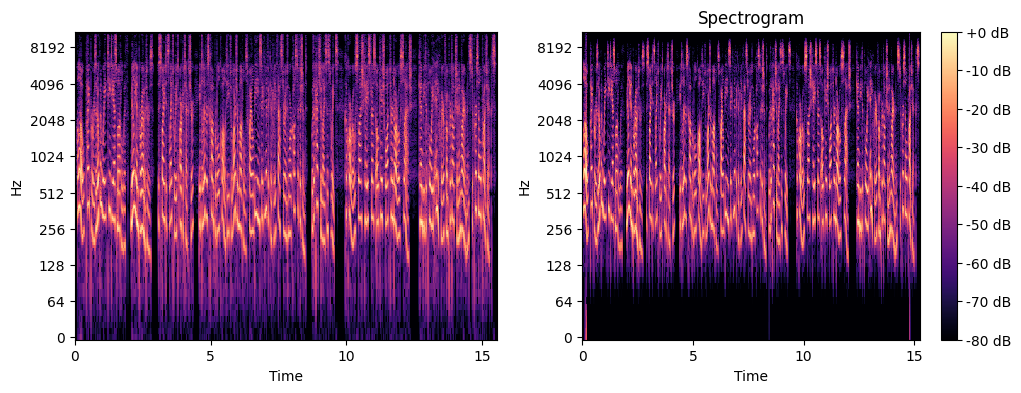

In [13]:
audio, sr = load_audio(audio_file)
processed_audio = apply_bandpass_filter(audio, sr)
processed_audio = reduce_noise(processed_audio, sr)
processed_audio = apply_agc(processed_audio)
processed_audio = apply_vad(processed_audio, sr)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(audio)), ref=np.max), y_axis='log', x_axis='time')
plt.subplot(1, 2, 2)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(processed_audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.show()

In [14]:
ipd.Audio(audio, rate=sr)

In [15]:
ipd.Audio(processed_audio, rate=sr)

## Whisper / Faster-Whisper comparison

In [42]:
audio_file = "./test_files/eng.wav"
# audio_file = "./test_files/rab-m3-n4.wav"
audio = load_audio(audio_file)[0]

### transcription-only

In [43]:
times_w, texts_w = [], []
times_fw, texts_fw = [], []

for _ in range(10):
    # whisper
    t0 = time.time()
    result = model_w.transcribe(
        audio,
        language="en",
    )
    times_w.append(time.time() - t0)
    texts_w.append(result["text"])

    # faster-whisper
    t1 = time.time()
    segments, info = model_fw.transcribe(
        audio,
        language="en",
        beam_size=3,
        temperature=0.0,
        condition_on_previous_text=False
    )
    times_fw.append(time.time() - t1)
    texts_fw.append(" ".join([seg.text for seg in segments]))

In [44]:
print(f"Whisper time mean: {np.mean(times_w):.2f} s - std: {np.std(times_w):.2f} s")
print(f"Faster-Whisper time mean: {np.mean(times_fw):.2f} s - std: {np.std(times_fw):.2f} s")

Whisper time mean: 0.99 s - std: 0.03 s
Faster-Whisper time mean: 0.02 s - std: 0.00 s


In [45]:
print(f"Whisper texts: {texts_w[0]}")

print(f"Faster-Whisper texts: {texts_fw[0]}")

Whisper texts:  The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health in zest. A salt pickle tastes fine with ham. Tuckles all pastora are my favorite. A zestful food is the hot cross bun.
Faster-Whisper texts:  The stale smell of old beer lingers.  It takes heat to bring out the odor.  A cold dip restores health in zest.  A salt pickle tastes fine with ham.  Tuckles all pastora are my favorite.  A zestful food is the hot cross bun.


### full pipeline

In [48]:
times_w, texts_w = [], []
times_fw, texts_fw = [], []

for _ in range(10):
    # whisper
    t0 = time.time()
    result = asr_pipeline(audio_file, lang="en", prompt="", faster=False)
    times_w.append(time.time() - t0)
    texts_w.append(result)

    # faster-whisper
    t1 = time.time()
    result = asr_pipeline(audio_file, lang="en", prompt="", faster=True)
    times_fw.append(time.time() - t1)
    texts_fw.append(result)

C:\Users\MATTIA\AppData\Roaming\Python\Python314\site-packages\whisper\transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


In [49]:
print(f"Whisper time mean: {np.mean(times_w):.2f} s - std: {np.std(times_w):.2f} s")
print(f"Faster-Whisper time mean: {np.mean(times_fw):.2f} s - std: {np.std(times_fw):.2f} s")

Whisper time mean: 2.20 s - std: 0.21 s
Faster-Whisper time mean: 1.52 s - std: 0.07 s


In [50]:
print(f"Whisper texts: {texts_w[0]}")

print(f"Faster-Whisper texts: {texts_fw[0]}")

Whisper texts: The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health in zest. A salt pickle tastes fine with ham. Tacos all pastora are my favorite. A zestful food is the hot cross bun.
Faster-Whisper texts: The stale smell of old beer lingers.  It takes heat to bring out the odor.  A cold dip restores health in zest.  A salt pickle tastes fine with ham.  Tacos all pastora are my favorite.  A zestful food is the hot cross bun.
